# Preprocessing — Implementation Cheatsheet

Theory: [preprocessing.md](preprocessing.md)

Everything that happens **between loading the data and fitting a model**. Mostly on the Customer Personality dataset (it has missing values, impossible outliers and messy categories).

| # | Section |
|---|---|
| 1 | Data quality checks |
| 2 | Missing values |
| 3 | Outliers |
| 4 | Encoding categoricals |
| 5 | Scaling |
| 6 | Feature engineering |
| 7 | Train/test split & data leakage |
| 8 | Putting it together: `ColumnTransformer` + `Pipeline` |

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression

cust = pd.read_csv("../data/customer_personality.csv", sep="\t")
cust.shape

(2240, 29)

## 1. Data quality checks

In [2]:
def quality_report(df):
    return pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(),
                         "missing_%": (df.isna().mean() * 100).round(1), "unique": df.nunique()})

rep = quality_report(cust)
print("duplicates (incl. ID):", cust.duplicated().sum(), "| without ID:", cust.drop(columns="ID").duplicated().sum())
rep[(rep["missing"] > 0) | (rep["unique"] <= 1) | (rep["unique"] == len(cust))]

duplicates (incl. ID): 0 | without ID: 182


,dtype,missing,missing_%,unique
ID,int64,0,0.0,2240
Income,float64,24,1.1,1974
Z_CostContact,int64,0,0.0,1
Z_Revenue,int64,0,0.0,1


Findings: `ID` is unique (drop it), `Z_CostContact` / `Z_Revenue` are constant (drop them), `Income` has missing values, and there are duplicates that only show up after dropping the ID.

In [3]:
df = cust.drop(columns=["ID", "Z_CostContact", "Z_Revenue"]).drop_duplicates().reset_index(drop=True)
print(df["Marital_Status"].value_counts().to_dict())       # messy categories

{'Married': 795, 'Together': 521, 'Single': 448, 'Divorced': 216, 'Widow': 71, 'Alone': 3, 'Absurd': 2, 'YOLO': 2}


## 2. Missing values

In [4]:
inc = df["Income"]
print(f"missing: {inc.isna().sum()} | mean {inc.mean():.0f} vs median {inc.median():.0f} | skew {inc.skew():.1f}")

missing: 24 | mean 52358 vs median 51533 | skew 7.1


Skewed column with outliers → **median** (the mean is pulled by extreme values). Options side by side:

In [5]:
options = pd.DataFrame({
    "drop rows": [len(df.dropna(subset=["Income"]))],
    "median": [df["Income"].fillna(df["Income"].median()).median()],
    "median by Education": [df["Income"].fillna(df.groupby("Education")["Income"].transform("median")).median()],
}, index=["rows kept / resulting median"]).T
options

,rows kept / resulting median
drop rows,2034.0
median,51533.0
median by Education,51650.5


In [6]:
# sklearn imputers (fit on TRAIN only inside a pipeline, see section 8)
num_cols = ["Income", "Year_Birth", "Kidhome", "Teenhome", "MntWines", "MntMeatProducts"]
simple = SimpleImputer(strategy="median").fit_transform(df[num_cols])
knn = KNNImputer(n_neighbors=5).fit_transform(df[num_cols])      # uses similar rows: often more realistic
missing_rows = df["Income"].isna().values
pd.DataFrame({"median imputer": simple[missing_rows, 0], "KNN imputer": knn[missing_rows, 0]}).head().round(0)

,median imputer,KNN imputer
0,51533.0,26389.0
1,51533.0,21006.0
2,51533.0,42163.0
3,51533.0,34513.0
4,51533.0,27885.0


The KNN imputer estimates much **lower** incomes for these customers than the global median, because their spending looks like low-income customers'. The median is simple and safe, but **KNN uses the other columns** and can be more realistic.

In [7]:
df["Income"] = df["Income"].fillna(df["Income"].median())
# Categorical missing values: mode, or an explicit "Unknown" category
# df[col] = df[col].fillna(df[col].mode()[0])   |   df[col] = df[col].fillna("Unknown")

## 3. Outliers
Two questions: **is it an error or real?** Errors get fixed/removed. Real extremes are kept, capped, or transformed.

In [8]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([.25, .75])
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)

out = []
for col in ["Year_Birth", "Income", "MntWines", "NumWebVisitsMonth"]:
    lo, hi = iqr_bounds(df[col])
    z = (df[col] - df[col].mean()) / df[col].std()
    out.append({"column": col, "IQR low": round(lo), "IQR high": round(hi),
                "IQR outliers": ((df[col] < lo) | (df[col] > hi)).sum(), "|z|>3": (z.abs() > 3).sum()})
pd.DataFrame(out)

,column,IQR low,IQR high,IQR outliers,|z|>3
0,Year_Birth,1932,2004,3,3
1,Income,-13109,117054,8,8
2,MntWines,-698,1226,33,14
3,NumWebVisitsMonth,-3,13,8,9


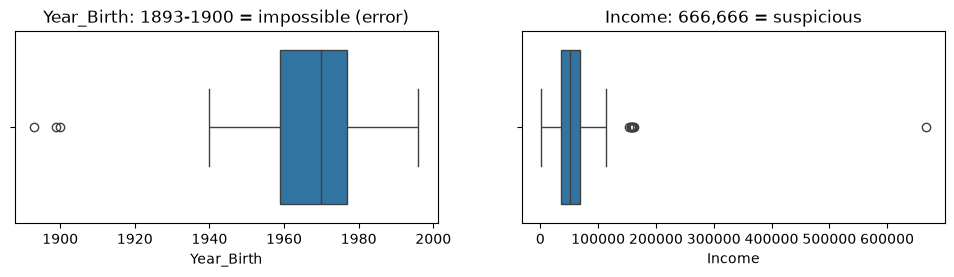

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 2.5))
sns.boxplot(x=df["Year_Birth"], ax=ax[0]).set_title("Year_Birth: 1893-1900 = impossible (error)")
sns.boxplot(x=df["Income"], ax=ax[1]).set_title("Income: 666,666 = suspicious")
plt.show()

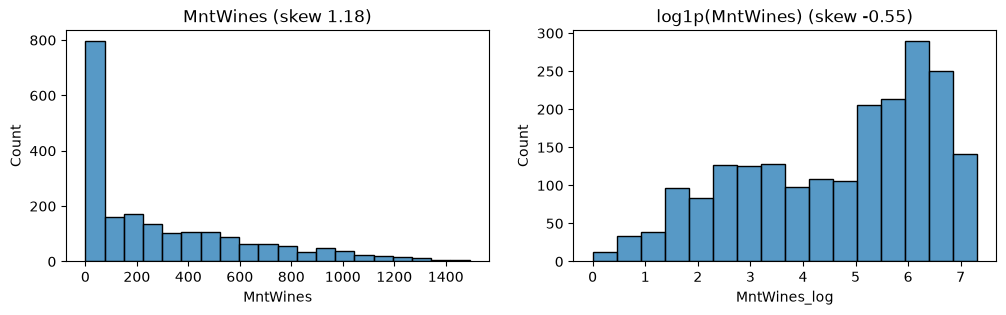

In [10]:
# 1) Errors -> remove
df = df[df["Year_Birth"] >= 1920]
# 2) Real but extreme -> cap (winsorize) at the IQR bounds
lo, hi = iqr_bounds(df["Income"])
df["Income_capped"] = df["Income"].clip(lower=lo, upper=hi)
# 3) Right-skewed -> log transform (log1p handles zeros)
df["MntWines_log"] = np.log1p(df["MntWines"])

fig, ax = plt.subplots(1, 2, figsize=(12, 3))
sns.histplot(df["MntWines"], ax=ax[0]).set_title(f"MntWines (skew {df['MntWines'].skew():.2f})")
sns.histplot(df["MntWines_log"], ax=ax[1]).set_title(f"log1p(MntWines) (skew {df['MntWines_log'].skew():.2f})")
plt.show()

## 4. Encoding categoricals

In [11]:
# Group rare / duplicate labels first
df["Marital_Status"] = df["Marital_Status"].replace({"Alone": "Single", "YOLO": "Other", "Absurd": "Other"})

# One-hot (nominal: no order). drop_first=True avoids the dummy trap for linear models
pd.get_dummies(df[["Marital_Status"]], drop_first=True, dtype=int).head(3)

,Marital_Status_Married,Marital_Status_Other,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow
0,0,0,1,0,0
1,0,0,1,0,0
2,0,0,0,1,0


In [12]:
# Ordinal (categories HAVE an order): map to ordered integers
edu_order = ["Basic", "2n Cycle", "Graduation", "Master", "PhD"]
df["Education_ord"] = df["Education"].map({e: i for i, e in enumerate(edu_order)})
df[["Education", "Education_ord"]].drop_duplicates().sort_values("Education_ord")

,Education,Education_ord
11,Basic,0
19,2n Cycle,1
0,Graduation,2
5,Master,3
4,PhD,4


In [13]:
# sklearn encoders (remember categories seen in train, safe for new data)
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(df[["Marital_Status"]])
print(ohe.get_feature_names_out())
print(OrdinalEncoder(categories=[edu_order]).fit_transform(df[["Education"]])[:5].ravel())

['Marital_Status_Divorced' 'Marital_Status_Married' 'Marital_Status_Other'
 'Marital_Status_Single' 'Marital_Status_Together' 'Marital_Status_Widow']
[2. 2. 2. 2. 4.]


## 5. Scaling
Needed for **distance / gradient** models (KNN, K-Means, SVM, PCA, linear with regularization, neural nets). **Not** needed for trees.

In [14]:
cols = ["Income", "MntWines", "Kidhome"]
scaled = {
    "original": df[cols],
    "StandardScaler (z-score)": pd.DataFrame(StandardScaler().fit_transform(df[cols]), columns=cols),
    "MinMaxScaler (0-1)": pd.DataFrame(MinMaxScaler().fit_transform(df[cols]), columns=cols),
    "RobustScaler (median/IQR)": pd.DataFrame(RobustScaler().fit_transform(df[cols]), columns=cols),
}
pd.concat({k: v.describe().loc[["mean", "std", "min", "max"]] for k, v in scaled.items()}).round(2)

Income  MntWines  Kidhome
original                  mean   52336.83    303.99     0.45
                          std    25384.00    336.50     0.54
                          min     1730.00      0.00     0.00
                          max   666666.00   1493.00     2.00
StandardScaler (z-score)  mean       0.00      0.00     0.00
                          std        1.00      1.00     1.00
                          min       -1.99     -0.90    -0.83
                          max       24.21      3.53     2.89
MinMaxScaler (0-1)        mean       0.08      0.20     0.22
                          std        0.04      0.23     0.27
                          min        0.00      0.00     0.00
                          max        1.00      1.00     1.00
RobustScaler (median/IQR) mean       0.02      0.27     0.45
                          std        0.78      0.70     0.54
                          min       -1.53     -0.36     0.00
                          max       18.92      2.74     2.00

Look at `Income` (it still contains the 666,666 outlier here): **MinMaxScaler** squeezes almost every customer into 0–0.1 because the max is extreme. **RobustScaler** (median & IQR) is barely affected. Outliers present → Robust; default → Standard; need a 0–1 range (images, some neural nets) → MinMax.

## 6. Feature engineering

In [15]:
fe = pd.DataFrame(index=df.index)
fe["Age"] = 2014 - df["Year_Birth"]                                                      # year -> age
fe["Children"] = df["Kidhome"] + df["Teenhome"]                                          # combine
fe["Total_Spend"] = df.filter(like="Mnt").drop(columns="MntWines_log").sum(axis=1)       # sum a family of columns
fe["Total_Purchases"] = df.filter(regex="^Num.*Purchases$").sum(axis=1)
fe["Avg_Ticket"] = fe["Total_Spend"] / fe["Total_Purchases"].replace(0, np.nan)          # ratio (avoid /0)
fe["Accepted_Any_Campaign"] = (df.filter(like="AcceptedCmp").sum(axis=1) > 0).astype(int)
fe["Enroll_Year"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y").dt.year         # date parts
fe.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Age,2055.0,45.1,11.7,18.0,37.0,44.0,55.0,74.0
Children,2055.0,1.0,0.7,0.0,0.0,1.0,1.0,3.0
Total_Spend,2055.0,606.2,602.4,5.0,69.0,397.0,1046.0,2525.0
Total_Purchases,2055.0,14.9,7.7,0.0,8.0,15.0,21.0,44.0
Avg_Ticket,2051.0,33.4,46.3,0.5,9.6,23.6,45.5,1679.0
Accepted_Any_Campaign,2055.0,0.2,0.4,0.0,0.0,0.0,0.0,1.0
Enroll_Year,2055.0,2013.0,0.7,2012.0,2013.0,2013.0,2014.0,2014.0


## 7. Train/test split & data leakage
**Leakage** = information from the test set (or the future) gets into training, so test scores are too optimistic.
Rule: **split first**, then `fit` imputers/scalers/encoders **on train only** and `transform` both.

In [16]:
X_tr, X_te = train_test_split(df[["Income", "MntWines"]], test_size=0.3, random_state=1)

scaler = StandardScaler().fit(X_tr)            # ✅ learn mean/std from TRAIN
X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)
print("train mean ≈ 0:", X_tr_s.mean(axis=0).round(3), "| test mean (not exactly 0, and that's correct):", X_te_s.mean(axis=0).round(3))
# ❌ StandardScaler().fit_transform(all_data) BEFORE splitting = leakage

train mean ≈ 0: [-0. -0.] | test mean (not exactly 0, and that's correct): [-0.045  0.032]


## 8. Putting it together: `ColumnTransformer` + `Pipeline`
One object that does impute → encode → scale → model. It **prevents leakage automatically** (inside CV, each fold fits its own preprocessing) and is what you'd deploy.
Example: ExtraaLearn lead conversion.

In [17]:
leads = pd.read_csv("../data/extraalearn.csv").drop(columns="ID").drop_duplicates()
X, y = leads.drop(columns="status"), leads["status"]
num_features = X.select_dtypes("number").columns.tolist()
cat_features = X.select_dtypes(exclude="number").columns.tolist()

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_features),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary"))]), cat_features),
])
model = Pipeline([("prep", preprocess), ("clf", LogisticRegression(class_weight="balanced", max_iter=1000))])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=1)
cv_recall = cross_val_score(model, X_train, y_train, cv=5, scoring="recall")
model.fit(X_train, y_train)
print(f"CV recall {cv_recall.mean():.3f} ± {cv_recall.std():.3f} | features after preprocessing: {len(model[:-1].get_feature_names_out())}")
model

CV recall 0.812 ± 0.009 | features after preprocessing: 19


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['age','current_occupation','first_interaction',...,'digital_media', 'educational_channels','referral']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder